# 03 — A far bigger model trades oil (GPT-5.1, through the OpenAI API)

Notebook 02 put a small open model on this laptop in the seat. This one plays **the same year, under the same rules, with the same three prompts** (P1 the basic brief, P2 plus risk rules, P3 a structured brief), with **GPT-5.1**, a frontier model reached through OpenAI's API. Same settings as September: the lowest reasoning setting (`reasoning_effort="low"`) and seed 7. GPT-5.1's training data stop at 30 September 2024, a year before the test year starts. OpenAI has deprecated GPT-5.1 and will shut it down on 1 April 2027.

**This notebook costs money.** It is built to be run in two stops:
1. **Sections 0 to 3** check the key, ask one day by hand, then play 10 days with P1 and project the time and cost of the full year. A few cents.
2. **Section 4** plays the full year (750 answers). It runs only after you set `RUN_FULL_YEAR = True` in the next cell, so *Run all* can never start it by accident.

Every answer is saved to disk the moment it arrives. Stopping and running again resumes where it stopped, and no answer is paid for twice.

**How an AI player decides.** Exactly as in notebook 02. Each day the model reads one of the three prompts and that day's data, and writes its answer: a position (long, short or flat), its chance that oil closes higher tomorrow (`p_up`), a one-line thesis and a short reasoning. It never sets a stop: the game places the same disaster stop on every position (three ATRs from entry, at most 15%). Nothing in the code makes the choice for it; there is no threshold on `p_up`; every day is a new decision. The written reasoning is a window, not proof: a language model's explanation does not always match how it reached its answer.

**One difference from Qwen.** GPT-5.1 is a reasoning model: OpenAI fixes its temperature, so two identical questions can get different answers. The saved answers make this run replayable exactly, but a fresh run might not repeat it.

In [1]:
import sys, os, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from oilbench import rules
from oilbench.data import Market, load_or_download
from oilbench.engine import Book
from oilbench.prompt import build_payload, render_text
from oilbench.agents import Flat, BuyAndHold, LLMAgent
from oilbench.backends import OpenAICompatibleBackend, load_env_file
from oilbench.replay import run, decision_dates, season_span, end_after, collect_saved
from oilbench.metrics import random_traders_cached, forecast_scores
from oilbench.live import LiveView
from oilbench.report import export_summary, load_summary, pnl_chart, luck_chart, trades_chart, calibration_chart, scoreboard, LABELS

MODEL = "gpt-5.1"
PREFIX = "gpt-5-1"
PROMPTS = ["P1", "P2", "P3"]
RUN_FULL_YEAR = True             # set to True only after reading the projected cost in section 3
# OpenAI list prices for GPT-5.1, USD per million tokens (check openai.com/api/pricing before running;
# the hidden reasoning tokens are billed as answer tokens)
PRICE_IN, PRICE_OUT = 1.25, 10.00
CACHE = ROOT / "data" / "llm_cache"
RESULTS = ROOT / "data" / "results"
SUMMARY_FOLDER = "summary"
SUMMARY = ROOT / "data" / SUMMARY_FOLDER

md_ = Market.from_raw(load_or_download(ROOT / "data" / "wti_daily.csv"), adjust_rolls=rules.ADJUST_ROLLS)
END = rules.WINDOW_END
span = season_span(md_, rules.WINDOW_START, END)
dds = decision_dates(md_, rules.WINDOW_START, END)
print(f"{span['days']} decisions; first trade at the open of {span['first_fill']}, last mark at the close of {span['last_mark']}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def cost(records):
    """USD for a list of answers, from the token counts OpenAI returned (saved with each answer)."""
    p = sum(r.prompt_tokens or 0 for r in records); c = sum(r.completion_tokens or 0 for r in records)
    return p * PRICE_IN / 1e6 + c * PRICE_OUT / 1e6, p, c

250 decisions; first trade at the open of 2025-10-02, last mark at the close of 2026-09-30


## 1. Is the key there, and does OpenAI answer?

The key is read from `local_settings.py` (never committed, never printed). Listing the models is free: no tokens are used.

In [2]:
load_env_file(ROOT)
assert os.environ.get("OPENAI_API_KEY"), "No OPENAI_API_KEY: put OPENAI_API_KEY = \"sk-...\" in local_settings.py"
print("✓ key found in local_settings.py (not shown)")
backend = OpenAICompatibleBackend("https://api.openai.com/v1", "OPENAI_API_KEY", reasoning_effort="low")   # as in September
models = backend.list_models()
assert MODEL in models, f"{MODEL} is not offered to this key"
print(f"✓ OpenAI answers, and {MODEL} is available")

✓ key found in local_settings.py (not shown)
✓ OpenAI answers, and gpt-5.1 is available


## 2. One day, by hand

One day with prompt P1: the answer and what it cost.

In [3]:
t = dds[0]
payload = build_payload(md_.asof(t), Book().snapshot(float(md_.bar(t)["close"])))
agent = LLMAgent(f"{PREFIX}_P1", backend, MODEL, prompt="P1", cache_dir=CACHE)
d = agent.decide(payload)
r = agent.records[-1]
usd, p_tok, c_tok = cost([r])
print(f"{t.date()}  WTI close {payload['price']}")
print(f"answer in {r.latency_s:.1f}s ({'from the saved answers' if r.cached else 'live'}), {p_tok} prompt tokens, "
      f"{c_tok} answer tokens (reasoning included), ${usd:.4f}, repaired: {r.repaired}\n")
print("POSITION :", d.position)
print("P_UP     :", d.p_up)
print("THESIS   :", d.thesis)
print("REASONING:", d.reasoning)

2025-10-01  WTI close 61.78
answer in 7.8s (from the saved answers), 2152 prompt tokens, 200 answer tokens (reasoning included), $0.0047, repaired: False

POSITION : short
P_UP     : 0.43
THESIS   : Downtrend intact with weak momentum; odds favor modest further downside over near-term rebound.
REASONING: Price below 20/50-day MAs, multi-week downtrend, RSI weak but not oversold, and recent bounces sold quickly. Trend-following favors downside continuation. Edge is modest.


## 3. Ten days with P1, and the projected time and cost of the year

The first 10 days of the year with P1, played through the real game. These answers are saved, so the full year reuses them for free.

In [4]:
end10 = end_after(md_, 10)
quick = LLMAgent(f"{PREFIX}_P1", backend, MODEL, prompt="P1", cache_dir=CACHE)
view = LiveView()
run(md_, [quick], rules.WINDOW_START, end10, on_day=view.day, on_decision=view.decision)
usd, p_tok, c_tok = cost(quick.records)
n = len(quick.records)
sec = np.mean([x.latency_s for x in quick.records])
n_year = span["days"] * len(PROMPTS)
print(f"\n{n} answers: {p_tok:,} prompt tokens, {c_tok:,} answer tokens, ${usd:.3f}, {sec:.1f}s per answer "
      f"({sum(x.repaired for x in quick.records)} repaired, {sum(bool(x.invalid) for x in quick.records)} invalid)")
print(f"PROJECTION for the full year, {len(PROMPTS)} prompts x {span['days']} days = {n_year} answers: "
      f"≈ ${usd / n * n_year:.0f} and ≈ {sec * n_year / 3600:.1f} h")
print("Answer tokens vary with the position held and with the prompt (P3 is longer), so treat this as a rough guide.")

2025-10-01  WTI  61.78  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.43  P&L    +208  Downtrend intact with weak momentum; odds favor modest further downsid
2025-10-02  WTI  60.48  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.42  P&L    +144  Maintain short in prevailing downtrend; price below key averages with 
2025-10-03  WTI  60.88  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.44  P&L     +13  Maintain short in established downtrend; momentum, MAs, and structure 
2025-10-06  WTI  61.69  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.45  P&L      +6  Downtrend intact; failed bounces and sub-SMA trade favor maintaining t
2025-10-07  WTI  61.73  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.47  P&L    -127  Maintain short in prevailing downtrend; recent bounce appears correcti
2025-10-08  WTI  62.55  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.46  P&L     +42  Maintain short: medium-term downtrend intact, bounce appears correctiv
2025-10-09  WTI  61.51  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.46 

## 4. Play the year (about an hour; costs money)

Runs only when `RUN_FULL_YEAR = True` in the first cell. One line per day for each prompt, as in notebook 02: the date, the WTI close, the position held after that day's decision, the disaster stop in force, the chance of a rise, the running P&L, and the one-line thesis.

Safe to interrupt (Kernel → Interrupt). If OpenAI stops answering, the run stops with a message rather than counting the missing days as decisions. Either way, running this cell again resumes from the saved answers.

In [5]:
if not RUN_FULL_YEAR:
    raise SystemExit("RUN_FULL_YEAR is False: read the projection in section 3, then set it to True in the first cell and run again.")
results, agents = {}, {}
for k in PROMPTS:
    name = f"{PREFIX}_{k}"
    agents[name] = LLMAgent(name, backend, MODEL, prompt=k, cache_dir=CACHE)
    print(f"\n==== {name}: {LABELS.get(name, name)} ====")
    view = LiveView()
    res = run(md_, [agents[name]], rules.WINDOW_START, END, on_day=view.day, on_decision=view.decision,
              log_dir=RESULTS / name)
    results[name] = res[name]
    a = agents[name]
    usd, p_tok, c_tok = cost(a.records)
    print(f"done: {len(a.records)} answers ({sum(x.cached for x in a.records)} saved earlier), "
          f"{sum(x.repaired for x in a.records)} repaired, {sum(bool(x.invalid) for x in a.records)} invalid, "
          f"cost of the whole prompt ${usd:.2f}, final P&L {res[name]['balance'].iloc[-1] - 10_000:+,.0f}")
total = cost([x for a in agents.values() for x in a.records])
print(f"\nAll three prompts: {total[1]:,} prompt tokens, {total[2]:,} answer tokens, ≈ ${total[0]:.2f} at list prices")


==== gpt-5-1_P1: GPT-5.1, Prompt 1 ====
2025-10-01  WTI  61.78  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.43  P&L    +208  Downtrend intact with weak momentum; odds favor modest further downsid
2025-10-02  WTI  60.48  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.42  P&L    +144  Maintain short in prevailing downtrend; price below key averages with 
2025-10-03  WTI  60.88  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.44  P&L     +13  Maintain short in established downtrend; momentum, MAs, and structure 
2025-10-06  WTI  61.69  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.45  P&L      +6  Downtrend intact; failed bounces and sub-SMA trade favor maintaining t
2025-10-07  WTI  61.73  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.47  P&L    -127  Maintain short in prevailing downtrend; recent bounce appears correcti
2025-10-08  WTI  62.55  gpt-5-1_P1     SHORT  stop   66.56  p_up 0.46  P&L     +42  Maintain short: medium-term downtrend intact, bounce appears correctiv
2025-10-09  WTI  61.51  gpt-5

## 5. The simple players, the random traders, and the summary

Do nothing and hold oil play the same days; the 1,000 random traders are the set saved for this exact window. Every player already played under the current rules (Qwen in notebook 02, TimesFM in notebook 04) is read back from `data/results/`, so the comparison includes whoever has run. The first Qwen run, under the old rules, is archived and not included. Everything is written to `data/summary/`, the folder the story notebook reads.

In [6]:
base = run(md_, [Flat(), BuyAndHold()], rules.WINDOW_START, END)
null = random_traders_cached(md_, ROOT / "data" / "results", rules.WINDOW_START, END,
                             on_batch=lambda done, n, s: print(f"\r  random traders {done}/{n}  {s:.0f}s", end=""))
print("\nrandom traders for the window", null["window"].iloc[0])
everything = {**collect_saved(RESULTS), **results, **base}
assert all(len(r["log"]) == span["days"] for r in everything.values()), "players must cover the same days (rerun any that do not)"
export_summary(everything, null, SUMMARY, {**span, "model": MODEL, "reasoning_effort": "low", "quick_look": False,
                                           "run_date": str(pd.Timestamp.today().date())})
S = load_summary(ROOT, SUMMARY_FOLDER)
LARGE = [LABELS[f"{PREFIX}_{k}"] for k in PROMPTS]
BASE = ["Do nothing (cash)", "Hold oil all year"]
OTHERS = [LABELS.get(k, k) for k in everything if k not in results and k not in ("flat", "buy_and_hold")]
print("summary written to", SUMMARY)
print("other players in the comparison:", ", ".join(OTHERS) if OTHERS else "none yet")


random traders for the window 2025-10-01_2026-09-29_250d_n1000
summary written to ./data/summary
other players in the comparison: Qwen3 8B, Prompt 1, Qwen3 8B, Prompt 2, Qwen3 8B, Prompt 3, TimesFM 2.5


## 6. Results

### The scoreboard and the P&L through the year

In [7]:
scoreboard(S, LARGE + BASE)

,"P&L, USD","Return on $10,000",Beats random traders (in 100),Trades,Winning trades,Stopped out,Days long / short / flat
player,,,,,,,
"GPT-5.1, Prompt 1","+1,406",+14.1%,72,21,29%,1,95 / 51 / 104
"GPT-5.1, Prompt 2","+3,516",+35.2%,82,11,45%,0,102 / 33 / 115
"GPT-5.1, Prompt 3",-5,-0.1%,61,26,19%,1,151 / 87 / 12
Do nothing (cash),+0,+0.0%,61,0,-,0,0 / 0 / 250
Hold oil all year,"+4,630",+46.3%,86,1,100%,0,250 / 0 / 0


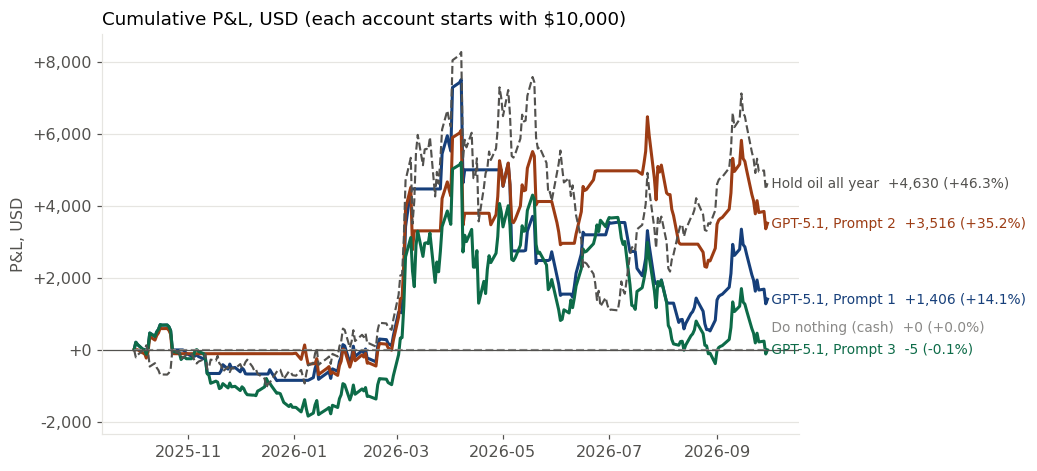

In [8]:
pnl_chart(S, LARGE + BASE);

### Skill or luck? Where each prompt lands among the 1,000 random traders

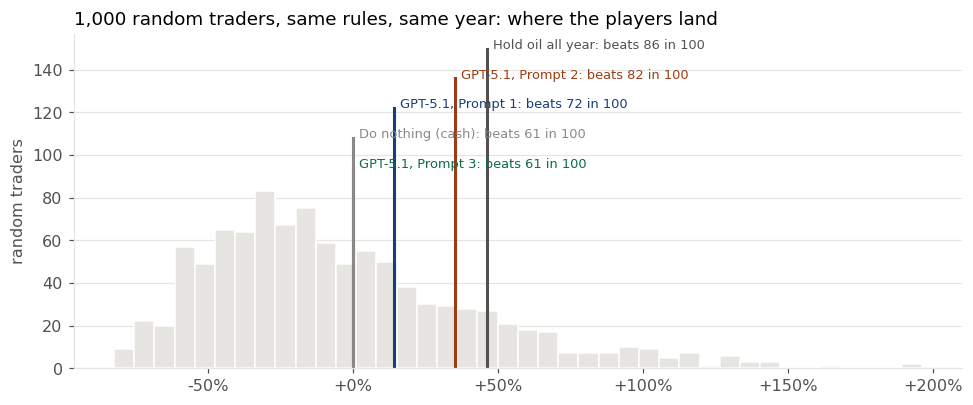

In [9]:
luck_chart(S, LARGE + BASE);

### The trades behind each result

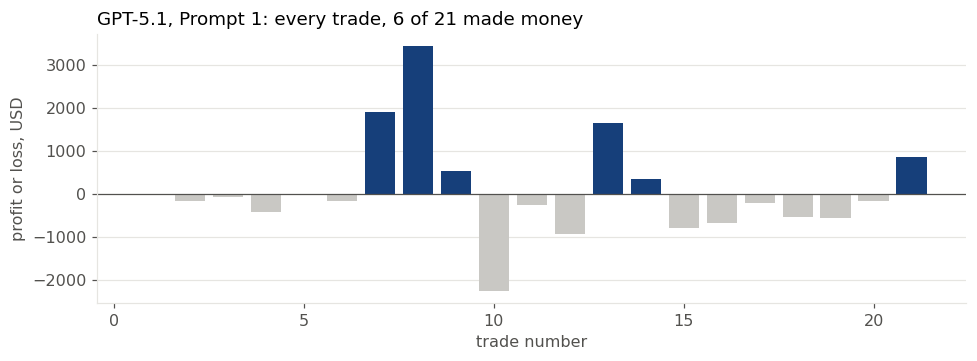

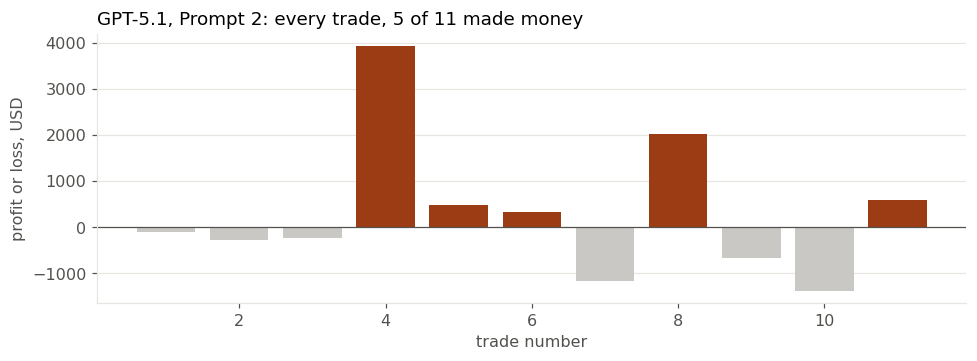

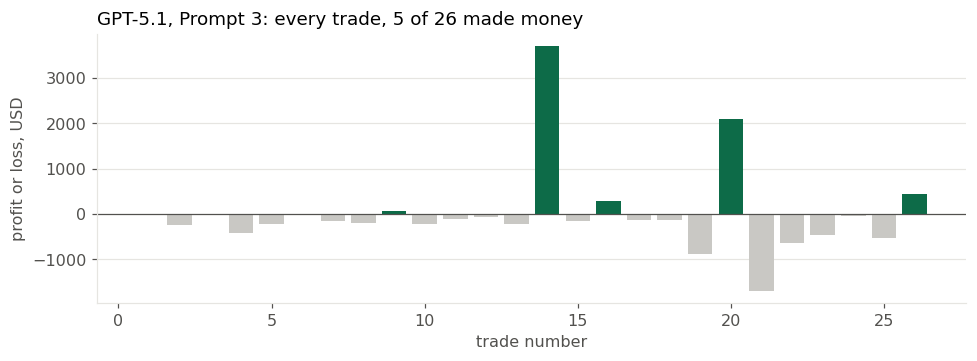

In [10]:
for p in LARGE:
    if not S.trades.empty and (S.trades["player"] == p).any():
        trades_chart(S, p); plt.show()

### How each prompt behaved

Days long, short and flat; how many times the model itself asked for a different position (starting from flat); how many trades ended at the disaster stop; and how many answers could not be used.

In [11]:
rows = []
for k in PROMPTS:
    name = f"{PREFIX}_{k}"; log = results[name]["log"]; tr = results[name]["trades"]
    before = log["held"].shift(fill_value="flat")
    rows.append({"prompt": k, "days long": int((log["held"] == "long").sum()), "days short": int((log["held"] == "short").sum()),
                 "days flat": int((log["held"] == "flat").sum()), "position changes asked": int((log["wanted"] != before).sum()),
                 "trades": len(tr), "stopped out": int((tr["reason"] == "stop").sum()) if len(tr) else 0,
                 "unusable answers": int((log["invalid"] != "").sum())})
pd.DataFrame(rows).set_index("prompt")

,days long,days short,days flat,position changes asked,trades,stopped out,unusable answers
prompt,,,,,,,
P1,95,51,104,39,21,1,0
P2,102,33,115,21,11,0,0
P3,151,87,12,35,26,1,0


### Did its daily chance of a rise mean anything?

A Brier score below 0.25 (always saying 50%) and a skill above zero would mean the numbers carry information.

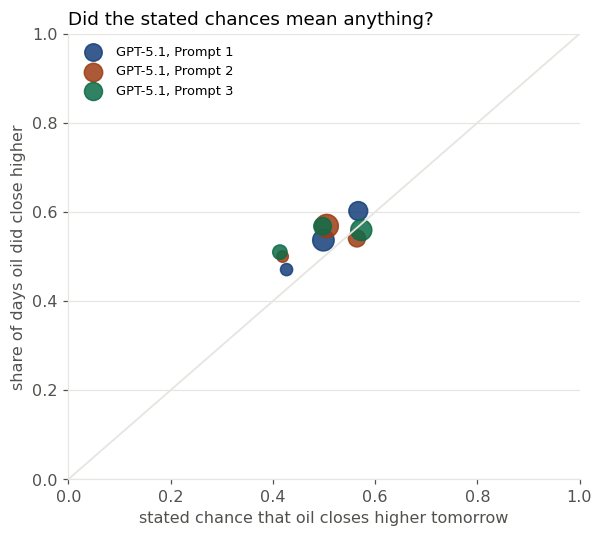

In [12]:
calibration_chart(S, LARGE);

In [13]:
fs = pd.DataFrame({k: forecast_scores(results[f"{PREFIX}_{k}"]["log"]) for k in PROMPTS}).T
fs[["n_forecasts", "n_missing", "mean_p_up", "distinct_values", "hit_rate", "share_up_days", "brier", "brier_no_view", "brier_skill"]].round(3)

,n_forecasts,n_missing,mean_p_up,distinct_values,hit_rate,share_up_days,brier,brier_no_view,brier_skill
P1,250.0,0.0,0.514,21.0,0.552,0.552,0.247,0.25,0.010
P2,250.0,0.0,0.512,20.0,0.510,0.552,0.250,0.25,-0.001
P3,250.0,0.0,0.516,24.0,0.512,0.552,0.253,0.25,-0.012


### A few days in the model's own words

The first six days on which the model asked for a different position (prompt P3), with what happened to the request.

In [14]:
log = results[f"{PREFIX}_P3"]["log"]
before = log["held"].shift(fill_value="flat")
asked = log[log["wanted"] != before].head(6)
for _, r in asked.iterrows():
    outcome = ("closed the position" if r["wanted"] == "flat" and r["held"] == "flat" else
               "opened" if r["held"] == r["wanted"] else
               "disaster stop hit the same session" if r["closed_trades"] else "not filled")
    print(f"{r['decision_date']}  WTI {r['close']:.2f}  asked {r['wanted'].upper()} ({outcome})  p_up {r['p_up']}\n   {r['reasoning']}\n")

2025-10-01  WTI 61.78  asked SHORT (opened)  p_up 0.42
   Trend is clearly down on 20–60d horizon (negative returns, price below 20/50d SMA). Momentum weak with 5d loss ~5% and RSI below 50 but not oversold, and price close to 20d low. No strong reversal signs. Edge favors continuation lower, and expected move easily exceeds costs, so initiate short rather than stay flat.

2025-10-23  WTI 61.79  asked LONG (opened)  p_up 0.58
   Medium-term trend still down (ret_20d/60d negative, below 50d MA), but price is now above 20d MA, RSI neutral-bullish, and 5d/1d returns show strong upside momentum on high volume breakout from recent lows. Short-term dynamics favor continued squeeze higher, invalidating prior short thesis. Edge is modest but exceeds costs, so I reverse.

2025-10-30  WTI 60.57  asked FLAT (closed the position)  p_up 0.47
   60-day trend is down, 20-day trend flat; price only slightly above 20-day SMA and still below 50-day, suggesting weak or failed rebound. RSI ~49 and ret_5d 

### GPT-5.1 against every other player so far

Only players run under the current rules appear here; Qwen joins once notebook 02 has been rerun.

In [15]:
scoreboard(S, LARGE + OTHERS + BASE)

,"P&L, USD","Return on $10,000",Beats random traders (in 100),Trades,Winning trades,Stopped out,Days long / short / flat
player,,,,,,,
"GPT-5.1, Prompt 1","+1,406",+14.1%,72,21,29%,1,95 / 51 / 104
"GPT-5.1, Prompt 2","+3,516",+35.2%,82,11,45%,0,102 / 33 / 115
"GPT-5.1, Prompt 3",-5,-0.1%,61,26,19%,1,151 / 87 / 12
"Qwen3 8B, Prompt 1",-731,-7.3%,56,109,43%,0,82 / 84 / 84
"Qwen3 8B, Prompt 2","-3,566",-35.7%,27,97,47%,3,56 / 64 / 130
"Qwen3 8B, Prompt 3","+1,140",+11.4%,70,30,37%,2,124 / 92 / 34
TimesFM 2.5,"-3,452",-34.5%,28,52,48%,7,56 / 175 / 19
Do nothing (cash),+0,+0.0%,61,0,-,0,0 / 0 / 250
Hold oil all year,"+4,630",+46.3%,86,1,100%,0,250 / 0 / 0


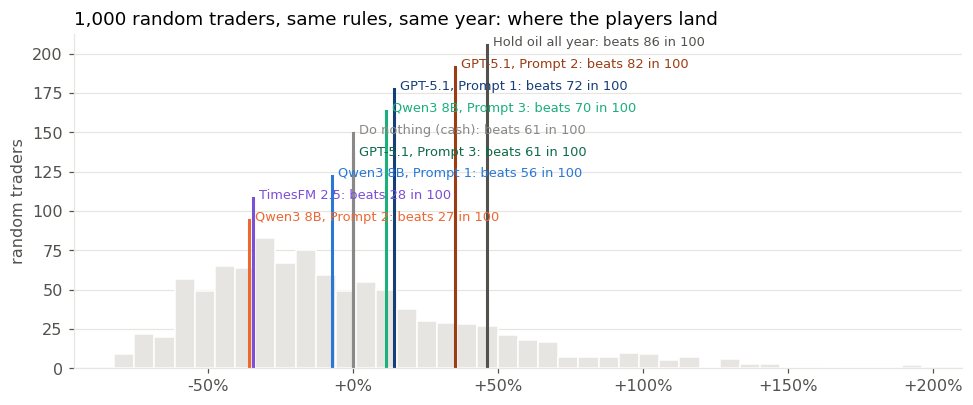

In [16]:
luck_chart(S, LARGE + OTHERS + BASE);

## 7. What this run found

**GPT-5.1, through OpenAI's API, played the test year (1 October 2025 to 30 September 2026) under the same rules and with the same three prompts as Qwen in notebook 02.** It ran at `reasoning_effort="low"`, seed 7. All 750 answers were usable and none needed repair. The whole year cost **$4.07** at list prices.

| Prompt | P&L | Beats random traders (in 100) | Trades | Days long / short / flat | Brier skill |
|---|---|---|---|---|---|
| P1, the basic brief | +$1,406 (+14.1%) | 72 | 21 | 95 / 51 / 104 | +0.010 |
| P2, plus risk rules | **+$3,516 (+35.2%)** | 82 | 11 | 102 / 33 / 115 | −0.001 |
| P3, a structured brief | −$5 (−0.1%) | 61 | 26 | 151 / 87 / 12 | −0.012 |
| Do nothing | $0 | 61 | 0 | 0 / 0 / 250 | |
| Hold oil all year | +$4,630 (+46.3%) | 86 | 1 | 250 / 0 / 0 | |

- **The bigger model did far better with the simpler briefs.** With P2, GPT-5.1 made +35.2%, while Qwen with the same brief lost −35.7%. With P1, it made +14.1% against Qwen's −7.3%. **It still did not beat simply holding oil.**
- **It traded rarely.** It made 11 to 26 trades in the year, against about 100 for Qwen with P1 and P2, paid $55 to $106 in fees, and with P1 and P2 sat flat on about 40% of days.
- **The best brief depended on the model.** P2 was GPT-5.1's best and Qwen's worst. P3 was Qwen's best and GPT-5.1's worst: break-even, with only 19% of its trades winning.
- **A couple of trades carried each result,** as with Qwen. With P2, a long from 26 January to 11 March made +$3,927 and a short in June made +$2,016; its other 9 trades lost −$2,426 between them. Every profitable run was long through March, when oil went from about $65 to over $100.
- **Gains were not kept.** With P1 the account peaked at +$7,513 in April and finished at +$1,406. P2 held up best: its worst drop from a peak was −25%, the smallest of any AI player.
- **Its stated chances of a rise were barely better than a coin.** With P1, its Brier skill was +0.010 and its direction was right on 55% of days: the only positive score of any player, but too small to claim forecasting skill. With P2 and P3 it was no better than always saying 50%.
- **Its reasoning reads like a trader's note.** It cites the 20 and 60-day trend, the averages, RSI and the 20-day range, and says when a thesis is "invalidated". Notebook 02 showed that convincing reasoning is not the same as a good result.

**Caveats.** Each prompt is one run. GPT-5.1 is a reasoning model whose temperature OpenAI fixes, so a fresh run could differ; the saved answers make this one replayable exactly. Each result rests on a few large trades, mostly made during the March spike.

Next: `04_timesfm.ipynb`, a model built for forecasting numbers.